# Exploratory SIAP harvest-price forecasts

Choose the products in `SELECTED_PRODUCTS` and enter each planned harvest in `CROP_ROTATION`. The notebook estimates **producer price in nominal MXN per tonne** at each crop's harvest. It derives the required horizon from the last planned harvest date: `x` is the number of calendar months after December of the latest SIAP file. Prices are aggregated as SIAP production value divided by production tonnes, so municipality and state prices are production-weighted rather than simple averages of rows.

SIAP's municipal closing files are **annual**. Models are fitted on annual observations and forecast annual prices; a harvest date selects its calendar year's forecast. The month within that year does not have a separately estimated seasonal price. When a selected crop has insufficient municipal observations, the notebook switches that crop to Guanajuato state data. It refuses to forecast a crop if neither geographic series meets the coverage and backtest checks. The coverage, chosen scope, and latest production volume are displayed; small volumes can make prices unstable.

A shared expanding-origin backtest evaluates a last-value baseline, damped Holt smoothing, ARIMA(1,1,0), lagged Ridge regression, and a lagged random forest. Every model for a crop uses the same held-out origin/year pairs and is ranked by **MAE in MXN/t**. Missing SIAP years are not used as observed holdouts; Holt and ARIMA interpolate internal gaps using only each training fold. This is exploratory, not a market-price guarantee. A long horizon and nominal prices are particularly uncertain; no inflation or future weather assumptions are included.

The final cell can add `estimated_price_mxn_t` and `estimated_gross_value_mxn` to a calibrated WOFOST output. Provide final harvest rows with crop, harvest date, and either estimated tonnes or calibrated t/ha plus area in ha. Gross value is tonnes × price, before costs, losses, and moisture-basis adjustments. The SIAP price series does not validate WOFOST yield.

In [1]:
import sys
from pathlib import Path
import pandas as pd

repo_root = next((path for path in (Path.cwd(), *Path.cwd().parents)
                  if (path / "gradientdescentfarmers" / "model_builder").is_dir()), None)
if repo_root is None:
    raise RuntimeError("Open this notebook within the repository or install the package")
sys.path.insert(0, str(repo_root))

from gradientdescentfarmers.model_builder.gcs import GCSDataClient
from gradientdescentfarmers.model_builder.price_forecasting import (
    add_prices_to_calibrated_wofost, compare_price_models,
    forecast_harvest_prices, load_siap_price_history,
    rotation_horizon, select_price_scope,
)

In [2]:
SELECTED_PRODUCTS = ["maize", "fababean"]
SIAP_CROP_LABELS = {"maize": "Maíz grano", "fababean": "Haba grano"}
STATE = "Guanajuato"
MUNICIPALITY = "Valle de Santiago"  # Carmelitas Chico locality
GCP_PROJECT = "gdfarming"
SIAP_YEARS = list(range(2003, 2026))  # municipal closing-file coverage in the bucket
LAST_SIAP_YEAR = max(SIAP_YEARS)

# Example future crop rotation; replace dates with the pipeline's planned harvests.
CROP_ROTATION = [
    {"crop": "maize", "harvest_date": "2027-10-20"},
    {"crop": "fababean", "harvest_date": "2028-05-20"},
]

# Optional: a CSV with final calibrated WOFOST harvest rows. Required columns:
# crop, harvest_date, and either estimated_tonnes or calibrated_t_ha + area_ha.
CALIBRATED_WOFOST_CSV = None

if not set(SELECTED_PRODUCTS).issubset(SIAP_CROP_LABELS):
    raise ValueError("Add an exact SIAP label for every selected product")
harvests_df, horizon_months, horizon_years = rotation_horizon(
    SELECTED_PRODUCTS, CROP_ROTATION, last_siap_year=LAST_SIAP_YEAR
)
print(f"Forecast horizon: {horizon_months} calendar months through {harvests_df.harvest_date.max().date()}")
print(f"Annual forecast years: {LAST_SIAP_YEAR + 1}–{LAST_SIAP_YEAR + horizon_years}")
display(harvests_df)

Forecast horizon: 29 calendar months through 2028-05-20
Annual forecast years: 2026–2028


,crop,harvest_date,forecast_year,months_ahead
0,maize,2027-10-20,2027,22
1,fababean,2028-05-20,2028,29


In [3]:
gcs = GCSDataClient(project=GCP_PROJECT)
prices_df = load_siap_price_history(
    gcs, years=SIAP_YEARS, state=STATE, municipality=MUNICIPALITY,
    crop_labels={crop: SIAP_CROP_LABELS[crop] for crop in SELECTED_PRODUCTS},
)
coverage_df = prices_df.groupby(["crop", "scope"], as_index=False).agg(
    observed_years=("year", "nunique"), first_year=("year", "min"),
    last_year=("year", "max"),
)
display(coverage_df)
display(prices_df.tail(12))

,crop,scope,observed_years,first_year,last_year
0,fababean,municipal,1,2005,2005
1,fababean,state,19,2003,2023
2,maize,municipal,23,2003,2025
3,maize,state,23,2003,2025


,year,crop,scope,production_t,value_mxn,price_mxn_t
54,2014,maize,state,1420029.46,4.009071e+09,2823.230704
55,2015,maize,state,1361922.09,4.655615e+09,3418.414797
56,2016,maize,state,1893920.40,6.724644e+09,3550.647799
57,2017,maize,state,1642835.37,5.772442e+09,3513.706735
58,2018,maize,state,1696776.49,6.679733e+09,3936.719193
59,2019,maize,state,1722978.37,6.324546e+09,3670.705323
60,2020,maize,state,1767544.31,8.023471e+09,4539.332381
61,2021,maize,state,1929919.25,1.156398e+10,5991.951000
62,2022,maize,state,1898924.59,1.414722e+10,7450.122749
63,2023,maize,state,1762462.60,1.372060e+10,7784.904418


In [4]:
selected_histories = {}
coverage_checks = []
for crop in SELECTED_PRODUCTS:
    crop_last_harvest_year = int(harvests_df.loc[
        harvests_df.crop == crop, "forecast_year"
    ].max())
    scope, history, checks = select_price_scope(
        prices_df, crop=crop, last_siap_year=LAST_SIAP_YEAR,
        horizon_years=crop_last_harvest_year - LAST_SIAP_YEAR,
    )
    selected_histories[crop] = history
    coverage_checks.append(checks)
    print(f"{crop}: selected {scope} prices, last priced year {int(history.year.max())}")
selection_df = pd.concat(coverage_checks, ignore_index=True)
display(selection_df)

maize: selected municipal prices, last priced year 2025
fababean: selected state prices, last priced year 2023


,crop,scope,observed_years,last_observed_year,last_production_t,missing_year_fraction,forecast_horizon_years,backtest_origins,eligible
0,maize,municipal,23,2025,103072.09,0.000000,2,5,True
1,fababean,municipal,1,2005,1.50,0.000000,23,0,False
2,fababean,state,19,2023,3.72,0.095238,5,5,True


In [5]:
backtest_frames = []
leaderboards = {}
model_failures = []
for crop, history in selected_histories.items():
    # A crop whose latest priced year precedes the last SIAP file needs extra steps.
    crop_last_harvest_year = int(harvests_df.loc[
        harvests_df.crop == crop, "forecast_year"
    ].max())
    crop_horizon_years = crop_last_harvest_year - int(history.year.max())
    backtest, leaderboard, failures = compare_price_models(
        history, horizon_years=crop_horizon_years,
    )
    backtest["crop"] = crop
    leaderboard["crop"] = crop
    leaderboard["scope"] = history.scope.iloc[0]
    leaderboard["forecast_horizon_years"] = crop_horizon_years
    backtest_frames.append(backtest)
    leaderboards[crop] = leaderboard
    if not failures.empty:
        failures["crop"] = crop
        model_failures.append(failures)
backtest_df = pd.concat(backtest_frames, ignore_index=True)
leaderboard_df = pd.concat(leaderboards.values(), ignore_index=True)
leaderboard_df = leaderboard_df.sort_values(["crop", "mae_mxn_t", "model"])
display(leaderboard_df[["crop", "scope", "model", "mae_mxn_t",
                        "holdout_points", "backtest_origins", "forecast_horizon_years"]])
if model_failures:
    display(pd.concat(model_failures, ignore_index=True))

,crop,scope,model,mae_mxn_t,holdout_points,backtest_origins,forecast_horizon_years
5,fababean,state,random_forest_lags,1927.470843,5,5,5
6,fababean,state,last_value,1942.878299,5,5,5
7,fababean,state,arima_110,2310.098329,5,5,5
8,fababean,state,holt_damped,3978.658710,5,5,5
9,fababean,state,ridge_lags,7426.682609,5,5,5
0,maize,municipal,ridge_lags,2105.619203,5,5,2
1,maize,municipal,last_value,2270.122695,5,5,2
2,maize,municipal,arima_110,2333.023354,5,5,2
3,maize,municipal,random_forest_lags,2346.038166,5,5,2
4,maize,municipal,holt_damped,2597.734797,5,5,2


In [6]:
annual_forecast_df, harvest_prices_df = forecast_harvest_prices(
    selected_histories, leaderboards, harvests_df,
    last_siap_year=LAST_SIAP_YEAR,
)
display(annual_forecast_df.sort_values(["crop", "forecast_year"]))
display(harvest_prices_df[["crop", "harvest_date", "months_ahead",
                           "estimated_price_mxn_t", "scope", "model",
                           "last_observed_year", "last_production_t",
                           "forecast_step_years"]])

output_dir = repo_root / "data" / "model_builder"
output_dir.mkdir(parents=True, exist_ok=True)
prices_df.to_csv(output_dir / "siap_selected_price_history.csv", index=False)
annual_forecast_df.to_csv(output_dir / "siap_annual_price_forecasts.csv", index=False)
harvest_prices_df.to_csv(output_dir / "siap_harvest_prices.csv", index=False)
leaderboard_df.to_csv(output_dir / "siap_price_model_comparison.csv", index=False)
backtest_df.to_csv(output_dir / "siap_price_backtest.csv", index=False)
print("Saved selected SIAP history, forecast, harvest-price, leaderboard, and backtest CSVs to", output_dir)

,crop,forecast_year,estimated_price_mxn_t,scope,model,last_siap_year,last_observed_year,last_production_t,forecast_step_years
2,fababean,2026,7280.634532,state,random_forest_lags,2025,2023,3.72,3
3,fababean,2027,7280.634532,state,random_forest_lags,2025,2023,3.72,4
4,fababean,2028,7280.634532,state,random_forest_lags,2025,2023,3.72,5
0,maize,2026,6040.966026,municipal,ridge_lags,2025,2025,103072.09,1
1,maize,2027,6595.891756,municipal,ridge_lags,2025,2025,103072.09,2


,crop,harvest_date,months_ahead,estimated_price_mxn_t,scope,model,last_observed_year,last_production_t,forecast_step_years
0,maize,2027-10-20,22,6595.891756,municipal,ridge_lags,2025,103072.09,2
1,fababean,2028-05-20,29,7280.634532,state,random_forest_lags,2023,3.72,5


Saved selected SIAP history, forecast, harvest-price, leaderboard, and backtest CSVs to /Users/allisonlara/Desktop/NASA/GradientDescentFarmers/data/model_builder


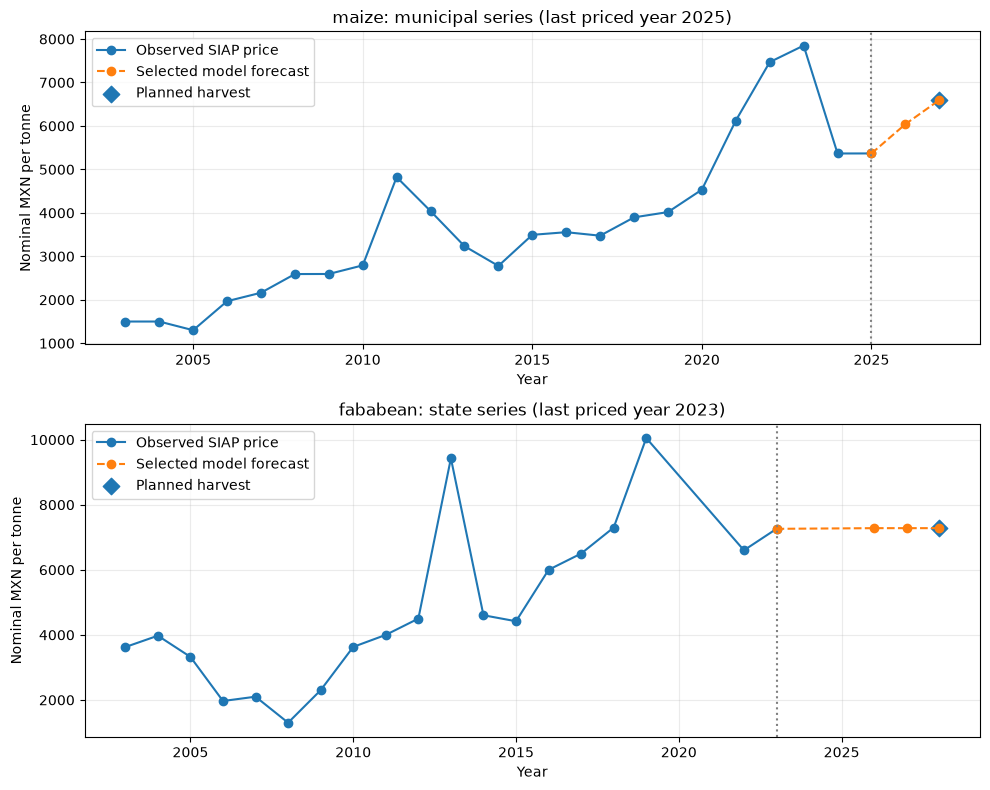

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(SELECTED_PRODUCTS), 1, figsize=(10, 4 * len(SELECTED_PRODUCTS)), squeeze=False)
for axis, crop in zip(axes.flat, SELECTED_PRODUCTS):
    history = selected_histories[crop]
    future = annual_forecast_df[annual_forecast_df.crop == crop].sort_values("forecast_year")
    harvest_points = harvest_prices_df[harvest_prices_df.crop == crop]
    axis.plot(history.year, history.price_mxn_t, marker="o", label="Observed SIAP price")
    axis.plot([int(history.year.max()), *future.forecast_year.tolist()],
              [float(history.price_mxn_t.iloc[-1]), *future.estimated_price_mxn_t.tolist()],
              marker="o", linestyle="--", label="Selected model forecast")
    axis.scatter(harvest_points.forecast_year, harvest_points.estimated_price_mxn_t,
                 marker="D", s=70, label="Planned harvest")
    axis.axvline(int(history.year.max()), color="gray", linestyle=":")
    axis.set(title=f"{crop}: {history.scope.iloc[0]} series (last priced year {int(history.year.max())})",
             xlabel="Year", ylabel="Nominal MXN per tonne")
    axis.grid(alpha=0.25)
    axis.legend()
fig.tight_layout()
fig.savefig(output_dir / "siap_price_history_and_forecast.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)

## Add prices to calibrated WOFOST harvests

Set `CALIBRATED_WOFOST_CSV` above to a CSV containing **future** final-harvest rows. The join uses crop and exact harvest date. If the calibrated yield is in t/ha, also provide cropped `area_ha`; the notebook calculates estimated tonnes before multiplying by the price. No synthetic yield or area is inserted here.

In [8]:
if CALIBRATED_WOFOST_CSV is None:
    print("Calibrated WOFOST join skipped: set CALIBRATED_WOFOST_CSV to final harvest rows.")
else:
    calibrated_wofost_df = pd.read_csv(CALIBRATED_WOFOST_CSV)
    valued_wofost_df = add_prices_to_calibrated_wofost(
        calibrated_wofost_df, harvest_prices_df
    )
    display(valued_wofost_df)
    valued_wofost_df.to_csv(output_dir / "calibrated_wofost_with_harvest_prices.csv", index=False)

Calibrated WOFOST join skipped: set CALIBRATED_WOFOST_CSV to final harvest rows.
